# 02 · Baselines

Two baselines on both datasets with the official splits and five seeds:

| Baseline | Model | Input |
|---|---|---|
| A | Text-only MLP | BERT vector of the root (news) node |
| B | Random Forest | Graph statistics of the propagation network, no text |

## 1 · Setup

In [1]:
import sys, os, json, time, platform, warnings, random, logging, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import scipy.sparse as sp
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import sklearn
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, precision_recall_fscore_support)

try:
    from tqdm.auto import tqdm
except ImportError:
    print("tqdm is not installed -> progress bars are disabled.  Install with: pip install tqdm")
    def tqdm(iterable=None, **kwargs):
        return iterable

try:
    import torch
    import torch.nn as nn
except ImportError:
    torch, nn = None, None
    print("PyTorch is NOT installed -> Baseline A (MLP) cannot run. Install from https://pytorch.org/get-started/locally/ "
          "(Windows / Pip / CUDA build matching your driver), then restart the kernel. Baseline B still works.")

try:
    import torch_geometric
    from torch_geometric.datasets import UPFD
    PYG_IMPORT_ERROR = None
except Exception as exc:
    torch_geometric, UPFD = None, None
    PYG_IMPORT_ERROR = repr(exc)
    print(f"torch_geometric not importable ({PYG_IMPORT_ERROR}). Only the optional PyG cross-check is affected. "
          "Install with: pip install torch_geometric")

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

versions = {"Python": sys.version.split()[0], "Platform": platform.platform(), "NumPy": np.__version__,
            "Pandas": pd.__version__, "SciPy": scipy.__version__, "scikit-learn": sklearn.__version__,
            "NetworkX": nx.__version__,
            "PyTorch": torch.__version__ if torch is not None else "NOT INSTALLED",
            "PyG": torch_geometric.__version__ if torch_geometric is not None else "NOT AVAILABLE"}
for k, v in versions.items():
    print(f"{k:<14}{v}")

if torch is not None and torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print(f"\nDevice: CUDA -> {torch.cuda.get_device_name(0)} ({torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB)")
else:
    DEVICE = torch.device("cpu") if torch is not None else "cpu"
    print("\nDevice: CPU (no CUDA available or PyTorch missing). The MLP is tiny, so CPU is perfectly adequate.")

Python        3.13.13
Platform      Windows-11-10.0.26200-SP0
NumPy         2.4.3
Pandas        2.3.3
SciPy         1.17.1
scikit-learn  1.8.0
NetworkX      3.6.1
PyTorch       2.11.0+cpu
PyG           2.8.1

Device: CPU (no CUDA available or PyTorch missing). The MLP is tiny, so CPU is perfectly adequate.


In [2]:
SEED = 42
FEATURE = "bert"
EXPECTED_FEATURE_DIM = 768
DATASETS = ["politifact", "gossipcop"]
DATASET_TITLES = {"politifact": "PolitiFact", "gossipcop": "GossipCop"}
SPLITS = ["train", "val", "test"]


FAKE_CLASS_INDEX = None
if FAKE_CLASS_INDEX is None:
    CLASS_NAMES = {0: "class 0", 1: "class 1"}
else:
    CLASS_NAMES = {FAKE_CLASS_INDEX: "fake", 1 - FAKE_CLASS_INDEX: "real"}
CLASS_COLORS = {0: "#0072B2", 1: "#D55E00"}


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "upfd").is_dir():
            return candidate
    for candidate in [start, *start.parents]:
        if (candidate / "notebooks").is_dir() and (candidate / "README.md").is_file():
            return candidate
    return start.parent if start.name == "notebooks" else start


PROJECT_ROOT = find_project_root()
UPFD_ROOT = PROJECT_ROOT / "data" / "upfd"
RESULTS_DIR = PROJECT_ROOT / "results"
METRICS_DIR = RESULTS_DIR / "metrics"
FIGURES_DIR = RESULTS_DIR / "figures"
LOGS_DIR = RESULTS_DIR / "logs"
CHECKPOINTS_DIR = RESULTS_DIR / "checkpoints"
for _d in (METRICS_DIR, FIGURES_DIR, LOGS_DIR, CHECKPOINTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Project root     :", PROJECT_ROOT)
print("UPFD data root   :", UPFD_ROOT, "(found)" if UPFD_ROOT.is_dir() else "(NOT FOUND)")
if not UPFD_ROOT.is_dir():
    raise FileNotFoundError(
        f"Could not find '{UPFD_ROOT}'. Start Jupyter from inside the project folder "
        "(e.g. `cd FakeNews-detection-GNN` then `jupyter lab`) so that data/upfd/ can be located."
    )


SAVED_ARTIFACTS = []


def _json_default(obj):
    if isinstance(obj, (np.integer,)):
        return int(obj)
    if isinstance(obj, (np.floating,)):
        return None if np.isnan(obj) else float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, Path):
        return str(obj)
    return str(obj)


def _register(path, kind):
    path = Path(path)
    try:
        shown = str(path.relative_to(PROJECT_ROOT))
    except ValueError:
        shown = str(path)
    SAVED_ARTIFACTS.append({"kind": kind, "path": shown, "size_kB": round(path.stat().st_size / 1024, 1)})


def save_figure(fig, path, dpi=150):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=dpi, bbox_inches="tight")
    _register(path, "figure")
    return path


def save_dataframe(df, path, index=False):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=index)
    _register(path, "csv")
    return path


def save_json(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, default=_json_default), encoding="utf-8")
    _register(path, "json")
    return path

Working directory: C:\Users\shara\FakeNews-detection-GNN\notebooks
Project root     : C:\Users\shara\FakeNews-detection-GNN
UPFD data root   : C:\Users\shara\FakeNews-detection-GNN\data\upfd (found)


In [3]:
REQUIRED_FILES = [
    "A.txt", "graph_labels.npy", "node_graph_id.npy",
    "train_idx.npy", "val_idx.npy", "test_idx.npy",
]
FEATURE_FILE = f"new_{FEATURE}_feature.npz"


def detect_layout(name, root=UPFD_ROOT):
    base = Path(root) / name
    required = REQUIRED_FILES + [FEATURE_FILE]
    problems = []
    for label, directory in (("raw", base / "raw"), ("flat", base)):
        if not directory.is_dir():
            problems.append(f"  - {directory}: directory does not exist")
            continue
        missing = [f for f in required if not (directory / f).is_file()]
        if not missing:
            return label, directory
        problems.append(f"  - {directory}: missing {missing}")
    raise FileNotFoundError(
        f"Could not find a complete UPFD '{name}' dataset under {base}.\n"
        + "\n".join(problems)
        + "\nThe files must be either directly inside that folder or inside its 'raw/' sub-folder."
    )


def load_feature_matrix(path):
    path = Path(path)
    try:
        X = sp.load_npz(path)
        kind = f"scipy.sparse ({X.format})"
    except Exception as sparse_error:
        try:
            with np.load(path, allow_pickle=False) as archive:
                arrays = {k: archive[k] for k in archive.files}
        except Exception as dense_error:
            raise ValueError(
                f"{path.name} is neither a SciPy sparse archive ({sparse_error!r}) "
                f"nor a readable NumPy archive ({dense_error!r})."
            )
        candidates = [k for k, v in arrays.items() if v.ndim == 2]
        if len(candidates) != 1:
            raise ValueError(
                f"{path.name} is not a SciPy sparse archive ({sparse_error!r}) and contains "
                f"{len(candidates)} two-dimensional arrays (keys: {list(arrays)}), so the feature "
                "matrix cannot be identified unambiguously."
            )
        X = sp.csr_matrix(arrays[candidates[0]])
        kind = f"dense array stored under key '{candidates[0]}'"
    return X.tocsr().astype(np.float32, copy=False), kind


def load_upfd_raw(name, load_features=True):
    layout, d = detect_layout(name)

    node_graph_id = np.load(d / "node_graph_id.npy", allow_pickle=False).reshape(-1).astype(np.int64)
    n_nodes = int(node_graph_id.shape[0])

    y_raw = np.load(d / "graph_labels.npy", allow_pickle=False).reshape(-1)
    classes_raw, y = np.unique(y_raw, return_inverse=True)
    y = np.asarray(y, dtype=np.int64).reshape(-1)
    n_graphs = int(y.shape[0])

    if node_graph_id.min() < 0 or node_graph_id.max() >= n_graphs:
        raise ValueError(
            f"[{name}] node_graph_id.npy contains ids in [{node_graph_id.min()}, {node_graph_id.max()}] "
            f"but graph_labels.npy describes {n_graphs} graphs (valid ids: 0..{n_graphs - 1})."
        )
    if np.any(np.diff(node_graph_id) < 0):
        raise ValueError(
            f"[{name}] node_graph_id.npy is not sorted, i.e. the nodes of one graph are not contiguous. "
            "The PyG-style slicing used here (and by PyG itself) would be wrong."
        )
    node_counts = np.bincount(node_graph_id, minlength=n_graphs)
    if np.any(node_counts == 0):
        raise ValueError(f"[{name}] {(node_counts == 0).sum()} graph id(s) own zero nodes.")
    node_slice = np.concatenate([[0], np.cumsum(node_counts)]).astype(np.int64)


    edges_raw = pd.read_csv(d / "A.txt", header=None, sep=",", skipinitialspace=True).to_numpy()
    if edges_raw.ndim != 2 or edges_raw.shape[1] != 2:
        raise ValueError(f"[{name}] A.txt should have exactly two comma-separated columns, got shape {edges_raw.shape}.")
    edges_raw = edges_raw.astype(np.int64)
    if edges_raw.min() < 0 or edges_raw.max() >= n_nodes:
        raise ValueError(
            f"[{name}] A.txt node ids range over [{edges_raw.min()}, {edges_raw.max()}] but there are "
            f"{n_nodes} nodes (valid: 0..{n_nodes - 1}). If the ids start at 1 the file is 1-indexed."
        )
    n_edges_raw = int(len(edges_raw))
    n_self_loops = int((edges_raw[:, 0] == edges_raw[:, 1]).sum())
    edges = np.unique(edges_raw, axis=0)
    n_duplicates = n_edges_raw - int(len(edges))
    key = edges[:, 0] * n_nodes + edges[:, 1]
    rev_key = edges[:, 1] * n_nodes + edges[:, 0]
    n_reciprocal = int((np.isin(rev_key, key) & (edges[:, 0] != edges[:, 1])).sum())

    src_gid = node_graph_id[edges[:, 0]]
    dst_gid = node_graph_id[edges[:, 1]]
    n_cross = int((src_gid != dst_gid).sum())
    if n_cross:
        raise ValueError(f"[{name}] {n_cross} edge(s) connect nodes that belong to different graphs.")
    if np.any(np.diff(src_gid) < 0):
        raise ValueError(f"[{name}] edges are not grouped by graph after sorting; slicing would be wrong.")
    edge_counts = np.bincount(src_gid, minlength=n_graphs)
    edge_slice = np.concatenate([[0], np.cumsum(edge_counts)]).astype(np.int64)


    X, feature_kind = (None, "not loaded")
    if load_features:
        X, feature_kind = load_feature_matrix(d / FEATURE_FILE)
        if X.shape[0] != n_nodes:
            raise ValueError(
                f"[{name}] {FEATURE_FILE} has {X.shape[0]} rows but node_graph_id.npy has {n_nodes} nodes."
            )


    splits = {}
    for s in SPLITS:
        idx = np.load(d / f"{s}_idx.npy", allow_pickle=False).reshape(-1).astype(np.int64)
        if len(idx) and (idx.min() < 0 or idx.max() >= n_graphs):
            raise ValueError(f"[{name}] {s}_idx.npy has indices outside 0..{n_graphs - 1}.")
        splits[s] = idx

    return {
        "name": name, "layout": layout, "dir": d,
        "X": X, "feature_kind": feature_kind,
        "edges": edges, "edge_slice": edge_slice, "node_slice": node_slice,
        "node_graph_id": node_graph_id, "y": y, "y_raw": y_raw, "classes_raw": classes_raw,
        "splits": splits, "n_nodes": n_nodes, "n_graphs": n_graphs,
        "audit": {
            "edges_in_A_txt": n_edges_raw, "unique_edges_after_coalesce": int(len(edges)),
            "duplicate_edges": n_duplicates, "self_loops": n_self_loops,
            "reciprocal_directed_edges": n_reciprocal, "cross_graph_edges": n_cross,
            "min_node_id": int(edges_raw.min()), "max_node_id": int(edges_raw.max()),
        },
    }


def graph_num_nodes(raw, i):
    return int(raw["node_slice"][i + 1] - raw["node_slice"][i])


def local_edges(raw, i):
    return raw["edges"][raw["edge_slice"][i]:raw["edge_slice"][i + 1]] - raw["node_slice"][i]


def root_features(raw, graph_indices):
    rows = raw["node_slice"][np.asarray(graph_indices, dtype=np.int64)]
    return raw["X"][rows].toarray()


def check_splits(raw):
    G = raw["n_graphs"]
    sets = {s: set(raw["splits"][s].tolist()) for s in SPLITS}
    rows = []
    for s in SPLITS:
        idx = raw["splits"][s]
        rows.append({
            "split": s, "n_indices": len(idx), "n_unique": len(sets[s]),
            "duplicates": len(idx) - len(sets[s]),
            "min_index": int(idx.min()) if len(idx) else None,
            "max_index": int(idx.max()) if len(idx) else None,
            "out_of_range": int(((idx < 0) | (idx >= G)).sum()),
        })
    overlaps = {f"{a} & {b}": len(sets[a] & sets[b]) for a, b in [("train", "val"), ("train", "test"), ("val", "test")]}
    union = set().union(*sets.values())
    coverage = {"graphs_in_union": len(union), "total_graphs": G, "graphs_in_no_split": G - len(union)}
    return pd.DataFrame(rows), overlaps, coverage


def root_convention_check(raw):
    rows = []
    for i in range(raw["n_graphs"]):
        n = graph_num_nodes(raw, i)
        e = local_edges(raw, i)
        indeg = np.bincount(e[:, 1], minlength=n)
        outdeg = np.bincount(e[:, 0], minlength=n)
        rows.append((i, n, len(e), int(indeg[0]), int(outdeg[0]), int((indeg == 0).sum()), int((outdeg == 0).sum())))
    df = pd.DataFrame(rows, columns=["graph_idx", "num_nodes", "num_edges", "node0_in_degree",
                                     "node0_out_degree", "n_sources", "n_sinks"])
    df["node0_unique_source"] = (df["node0_in_degree"] == 0) & (df["n_sources"] == 1)
    df["node0_unique_sink"] = (df["node0_out_degree"] == 0) & (df["n_sinks"] == 1)
    return df


def summarize_root_check(df, name):
    frac_source = float(df["node0_unique_source"].mean())
    frac_sink = float(df["node0_unique_sink"].mean())
    direction = ("edges point from node 0 (root) outwards: parent -> child"
                 if frac_source >= frac_sink else
                 "edges point towards node 0 (root): child -> parent")
    summary = {
        "dataset": name, "graphs": len(df),
        "node0_is_unique_source": f"{int(df['node0_unique_source'].sum())} / {len(df)}",
        "node0_is_unique_sink": f"{int(df['node0_unique_sink'].sum())} / {len(df)}",
        "edge_direction_inferred": direction,
        "graphs_with_edges_eq_nodes_minus_1": f"{int((df['num_edges'] == df['num_nodes'] - 1).sum())} / {len(df)}",
    }
    if max(frac_source, frac_sink) < 0.95:
        raise RuntimeError(
            f"[{name}] local node 0 is the unique root in only {max(frac_source, frac_sink):.1%} of graphs. "
            "The assumption 'graph.x[0] is the news node' is NOT supported by this data; stop and investigate."
        )
    if max(frac_source, frac_sink) < 1.0:
        bad = df.loc[~(df["node0_unique_source"] if frac_source >= frac_sink else df["node0_unique_sink"]), "graph_idx"]
        warnings.warn(f"[{name}] root convention violated in graphs {bad.head(10).tolist()} (showing up to 10).")
    return summary

In [4]:
def compute_graph_statistics(n_nodes, edges):
    n_edges = int(len(edges))
    G = nx.Graph()
    G.add_nodes_from(range(n_nodes))
    G.add_edges_from((int(a), int(b)) for a, b in edges if a != b)
    degree_map = dict(G.degree())
    degrees = np.array([degree_map[v] for v in range(n_nodes)], dtype=np.int64)
    depth_map = nx.single_source_shortest_path_length(G, 0)
    non_root_depths = np.array([dep for v, dep in depth_map.items() if v != 0], dtype=np.float64)
    connected = len(depth_map) == n_nodes
    leaf_count = int((degrees[1:] == 1).sum()) if n_nodes > 1 else 0
    return {
        "num_nodes": int(n_nodes),
        "num_edges": n_edges,
        "max_depth": int(max(depth_map.values())),
        "avg_depth": float(non_root_depths.mean()) if len(non_root_depths) else 0.0,
        "root_degree": int(degrees[0]),
        "max_degree": int(degrees.max()),
        "avg_degree": float(degrees.mean()),
        "degree_std": float(degrees.std()),
        "leaf_count": leaf_count,
        "leaf_proportion": leaf_count / n_nodes,
        "is_connected": bool(connected),
        "is_tree": bool(connected and G.number_of_edges() == n_nodes - 1),
    }


def compute_all_graph_statistics(raw, desc=None):
    rows = []
    for i in tqdm(range(raw["n_graphs"]), desc=desc or raw["name"], leave=False):
        row = compute_graph_statistics(graph_num_nodes(raw, i), local_edges(raw, i))
        row["graph_idx"] = i
        rows.append(row)
    df = pd.DataFrame(rows)
    gi = df["graph_idx"].to_numpy()
    df["label"] = raw["y"][gi]
    df["label_raw"] = raw["y_raw"][gi]
    split = np.full(raw["n_graphs"], "unassigned", dtype=object)
    for s_name, idx in raw["splits"].items():
        split[idx] = s_name
    df["split"] = split[gi]
    first = ["graph_idx", "split", "label", "label_raw"]
    return df[first + [c for c in df.columns if c not in first]]

In [5]:
def load_pyg_splits(name):
    if UPFD is None:
        raise RuntimeError(f"torch_geometric could not be imported ({PYG_IMPORT_ERROR}).")
    layout, _ = detect_layout(name)
    if layout != "raw":
        raise RuntimeError(
            f"The '{name}' files are directly inside data/upfd/{name}/ (layout 'flat'). "
            "torch_geometric.datasets.UPFD only looks in data/upfd/<name>/raw/. As instructed, this notebook "
            "does not move your files, so the PyG cross-check is skipped for this dataset."
        )
    return {s: UPFD(root=str(UPFD_ROOT), name=name, feature=FEATURE, split=s) for s in SPLITS}


def crosscheck_with_pyg(raw, pyg_sets, n_random=25, seed=SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for s, ds in pyg_sets.items():
        idx = raw["splits"][s]
        picks = {0, len(ds) - 1}
        picks.update(rng.choice(len(ds), size=min(n_random, len(ds)), replace=False).tolist())
        mismatches = {"nodes": 0, "edges": 0, "label": 0, "root_feature": 0}
        for k in sorted(picks):
            g, i = ds[int(k)], int(idx[k])
            mismatches["nodes"] += int(g.num_nodes != graph_num_nodes(raw, i))
            mismatches["edges"] += int(not np.array_equal(g.edge_index.t().cpu().numpy(), local_edges(raw, i)))
            mismatches["label"] += int(int(g.y.view(-1)[0].item()) != int(raw["y"][i]))
            ours = raw["X"][raw["node_slice"][i]].toarray().ravel()
            mismatches["root_feature"] += int(not np.allclose(g.x[0].cpu().numpy(), ours))
        rows.append({"split": s, "pyg_len": len(ds), "our_len": len(idx),
                     "length_match": len(ds) == len(idx), "graphs_compared": len(picks), **mismatches})
    return pd.DataFrame(rows)

## 2 · Settings

In [6]:
SEEDS = [42, 43, 44, 45, 46]

MLP_HP = {
    "hidden_dim": 128,
    "dropout": 0.5,
    "lr": 1e-3,
    "weight_decay": 1e-4,
    "batch_size": 32,
    "max_epochs": 300,
    "patience": 30,
    "min_delta": 1e-4,
    "standardize": True,
}
RF_FIXED = {"n_estimators": 200}
RF_GRID = {"max_depth": [None, 4, 8], "min_samples_leaf": [1, 3, 5]}

BASE_METRICS_DIR = METRICS_DIR / "baselines"
BASE_FIG_DIR = FIGURES_DIR / "baselines"
BASE_LOG_DIR = LOGS_DIR / "baselines"
BASE_CKPT_DIR = CHECKPOINTS_DIR / "baselines"
for _d in (BASE_METRICS_DIR, BASE_FIG_DIR, BASE_LOG_DIR, BASE_CKPT_DIR):
    _d.mkdir(parents=True, exist_ok=True)

RUN_ID = time.strftime("%Y%m%d_%H%M%S")
LOG_PATH = BASE_LOG_DIR / f"baselines_{RUN_ID}.log"
logger = logging.getLogger("baselines")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_fh = logging.FileHandler(LOG_PATH, mode="a", encoding="utf-8")
_fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(_fh)
logger.info("Notebook 02 started. seeds=%s device=%s versions=%s", SEEDS, DEVICE, versions)
print("Log file:", LOG_PATH.relative_to(PROJECT_ROOT))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    if torch is not None:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False


def require_torch():
    if torch is None:
        raise ImportError("PyTorch is required for the text-only MLP. Install it from "
                          "https://pytorch.org/get-started/locally/ (Windows / Pip / matching CUDA build), "
                          "restart the kernel and re-run from the top.")

Log file: results\logs\baselines\baselines_20261108_130203.log


## 3 · Load data and checks

In [7]:
RAW = {}
for name in DATASETS:
    t0 = time.perf_counter()
    RAW[name] = load_upfd_raw(name)
    r = RAW[name]
    print(f"{DATASET_TITLES[name]:<11} loaded in {time.perf_counter() - t0:5.1f}s | layout={r['layout']:<4} | graphs={r['n_graphs']:,} | "
          f"nodes={r['n_nodes']:,} | features {r['X'].shape}")
    assert len(r["classes_raw"]) == 2, f"{name}: expected 2 classes, got {r['classes_raw']}"
    assert r["X"].shape[1] == EXPECTED_FEATURE_DIM, f"{name}: feature dim {r['X'].shape[1]} != {EXPECTED_FEATURE_DIM}"

    split_df, overlaps, coverage = check_splits(r)
    assert all(v == 0 for v in overlaps.values()), f"{name}: splits overlap {overlaps} -> data leakage!"
    assert split_df["duplicates"].sum() == 0 and split_df["out_of_range"].sum() == 0
    print(f"   splits (train/val/test graphs): {[len(r['splits'][s]) for s in SPLITS]} | overlaps: {overlaps} | coverage: {coverage}")

ROOT_CHECK = {name: root_convention_check(RAW[name]) for name in DATASETS}
display(pd.DataFrame([summarize_root_check(ROOT_CHECK[n], DATASET_TITLES[n]) for n in DATASETS]).set_index("dataset").T)

label_rows = []
for name in DATASETS:
    r = RAW[name]
    cnt = np.bincount(r["y"], minlength=2)
    for c in (0, 1):
        label_rows.append({"dataset": DATASET_TITLES[name], "raw_label_value": r["classes_raw"][c].item(), "class_index": c,
                           "name_used_here": CLASS_NAMES[c], "graphs": int(cnt[c])})
display(pd.DataFrame(label_rows))
if FAKE_CLASS_INDEX is None:
    print("LABEL SEMANTICS UNVERIFIED: classes are reported as class 0 / class 1. ROC-AUC and the macro-averaged "
          "metrics are unaffected by which class is 'fake'; per-class precision/recall are saved for both classes.")

PolitiFact  loaded in   5.2s | layout=flat | graphs=314 | nodes=41,054 | features (41054, 768)
   splits (train/val/test graphs): [62, 31, 221] | overlaps: {'train & val': 0, 'train & test': 0, 'val & test': 0} | coverage: {'graphs_in_union': 314, 'total_graphs': 314, 'graphs_in_no_split': 0}
GossipCop   loaded in  33.5s | layout=flat | graphs=5,464 | nodes=314,262 | features (314262, 768)
   splits (train/val/test graphs): [1092, 546, 3826] | overlaps: {'train & val': 0, 'train & test': 0, 'val & test': 0} | coverage: {'graphs_in_union': 5464, 'total_graphs': 5464, 'graphs_in_no_split': 0}


dataset,PolitiFact,GossipCop
graphs,314,5464
node0_is_unique_source,314 / 314,5464 / 5464
node0_is_unique_sink,0 / 314,0 / 5464
edge_direction_inferred,edges point from node 0 (root) outwards: paren...,edges point from node 0 (root) outwards: paren...
graphs_with_edges_eq_nodes_minus_1,314 / 314,5464 / 5464


,dataset,raw_label_value,class_index,name_used_here,graphs
0,PolitiFact,0.0,0,class 0,157
1,PolitiFact,1.0,1,class 1,157
2,GossipCop,0.0,0,class 0,2732
3,GossipCop,1.0,1,class 1,2732


LABEL SEMANTICS UNVERIFIED: classes are reported as class 0 / class 1. ROC-AUC and the macro-averaged metrics are unaffected by which class is 'fake'; per-class precision/recall are saved for both classes.


In [8]:
for name in DATASETS:
    try:
        pyg_sets = load_pyg_splits(name)
        rep = crosscheck_with_pyg(RAW[name], pyg_sets)
        display(rep)
        ok = rep["length_match"].all() and rep[["nodes", "edges", "label", "root_feature"]].to_numpy().sum() == 0
        print(f"{DATASET_TITLES[name]}: PyG cross-check", "PASSED" if ok else "MISMATCH -> investigate")
        logger.info("PyG cross-check %s: %s", name, "passed" if ok else "MISMATCH")
        del pyg_sets
    except Exception as exc:
        print(f"{DATASET_TITLES[name]}: PyG cross-check NOT PERFORMED -> {exc}")
        logger.info("PyG cross-check %s not performed: %s", name, exc)

PolitiFact: PyG cross-check NOT PERFORMED -> The 'politifact' files are directly inside data/upfd/politifact/ (layout 'flat'). torch_geometric.datasets.UPFD only looks in data/upfd/<name>/raw/. As instructed, this notebook does not move your files, so the PyG cross-check is skipped for this dataset.
GossipCop: PyG cross-check NOT PERFORMED -> The 'gossipcop' files are directly inside data/upfd/gossipcop/ (layout 'flat'). torch_geometric.datasets.UPFD only looks in data/upfd/<name>/raw/. As instructed, this notebook does not move your files, so the PyG cross-check is skipped for this dataset.


## 4 · Evaluation helpers

In [9]:
SHOW_PLOTS = True


def show_or_close(fig):
    if SHOW_PLOTS:
        plt.show()
    else:
        plt.close(fig)


show_cols = ["dataset", "seed", "split", "n", "accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc"]


def compute_metrics(y_true, y_pred, y_score):
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    out = {
        "n": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan,
    }
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    for c in (0, 1):
        out[f"precision_class{c}"], out[f"recall_class{c}"], out[f"f1_class{c}"], out[f"support_class{c}"] = p[c], r[c], f[c], int(s[c])
    if FAKE_CLASS_INDEX is not None:
        real = 1 - FAKE_CLASS_INDEX
        out["precision_fake"], out["recall_fake"] = p[FAKE_CLASS_INDEX], r[FAKE_CLASS_INDEX]
        out["precision_real"], out["recall_real"] = p[real], r[real]
    return out


def plot_confusion(y_true, y_pred, title, path):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    names = [CLASS_NAMES[0], CLASS_NAMES[1]]
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, xticklabels=names, yticklabels=names, ax=axes[0])
    axes[0].set_title("counts"); axes[0].set_xlabel("predicted"); axes[0].set_ylabel("true")
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, xticklabels=names, yticklabels=names, ax=axes[1])
    axes[1].set_title("row-normalised (recall per class)"); axes[1].set_xlabel("predicted"); axes[1].set_ylabel("true")
    fig.suptitle(title); plt.tight_layout()
    save_figure(fig, path); show_or_close(fig)
    return cm


def plot_roc(y_true, y_score, auc, title, path):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    fig, ax = plt.subplots(figsize=(4.8, 4.5))
    ax.plot(fpr, tpr, lw=2, label=f"AUC = {auc:.3f}")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="chance")
    ax.set_xlabel("false-positive rate (class 1 = positive)"); ax.set_ylabel("true-positive rate"); ax.set_title(title); ax.legend(loc="lower right")
    plt.tight_layout(); save_figure(fig, path); show_or_close(fig)


def append_run_metrics(rows, csv_path):
    new = pd.DataFrame(rows)
    if csv_path.is_file():
        old = pd.read_csv(csv_path)
        key = ["dataset", "model", "seed", "split"]
        old = old.merge(new[key].drop_duplicates(), on=key, how="left", indicator=True)
        old = old[old["_merge"] == "left_only"].drop(columns="_merge")
        new = pd.concat([old, new], ignore_index=True)
    save_dataframe(new, csv_path)
    return new

## 5 · Baseline A: Text-only MLP

Input is the root-node BERT vector (768 numbers). Model: `Linear(768, 128) → ReLU → Dropout(0.5) → Linear(128, 2)`, trained with Adam and early stopping on validation loss. Features are standardised using training data only. Plots are shown for the first seed only.

In [10]:
def build_text_dataset(raw):
    data = {}
    for s in SPLITS:
        idx = raw["splits"][s]
        data[s] = {"idx": idx, "X": root_features(raw, idx).astype(np.float32), "y": raw["y"][idx]}
        assert data[s]["X"].shape == (len(idx), EXPECTED_FEATURE_DIM)

    assert not (set(data["train"]["idx"]) & set(data["test"]["idx"])) and not (set(data["train"]["idx"]) & set(data["val"]["idx"]))
    return data


TEXT_DATA = {name: build_text_dataset(RAW[name]) for name in DATASETS}
rows = []
for name in DATASETS:
    for s in SPLITS:
        d = TEXT_DATA[name][s]
        cnt = np.bincount(d["y"], minlength=2)
        rows.append({"dataset": DATASET_TITLES[name], "split": s, "X shape": d["X"].shape, "y shape": d["y"].shape,
                     "class 0": int(cnt[0]), "class 1": int(cnt[1]), "class-1 share": round(cnt[1] / cnt.sum(), 3)})
display(pd.DataFrame(rows))

,dataset,split,X shape,y shape,class 0,class 1,class-1 share
0,PolitiFact,train,"(62, 768)","(62,)",36,26,0.419
1,PolitiFact,val,"(31, 768)","(31,)",13,18,0.581
2,PolitiFact,test,"(221, 768)","(221,)",108,113,0.511
3,GossipCop,train,"(1092, 768)","(1092,)",557,535,0.490
4,GossipCop,val,"(546, 768)","(546,)",265,281,0.515
5,GossipCop,test,"(3826, 768)","(3826,)",1910,1916,0.501


In [11]:
def build_mlp(in_dim, hidden_dim, dropout, n_classes=2):
    require_torch()
    return nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.ReLU(), nn.Dropout(dropout), nn.Linear(hidden_dim, n_classes))


def predict_mlp(model, X, device):
    model.eval()
    with torch.no_grad():
        logits = model(torch.as_tensor(X, dtype=torch.float32, device=device))
        proba = torch.softmax(logits, dim=1).cpu().numpy()
    return proba.argmax(axis=1), proba[:, 1]


def train_mlp(Xtr, ytr, Xva, yva, seed, hp, device):
    require_torch()
    set_seed(seed)
    model = build_mlp(Xtr.shape[1], hp["hidden_dim"], hp["dropout"]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    Xtr_t = torch.as_tensor(Xtr, dtype=torch.float32, device=device)
    ytr_t = torch.as_tensor(ytr, dtype=torch.long, device=device)
    Xva_t = torch.as_tensor(Xva, dtype=torch.float32, device=device)
    yva_t = torch.as_tensor(yva, dtype=torch.long, device=device)
    gen = torch.Generator().manual_seed(seed)

    n, history = len(Xtr_t), []
    best_val, best_epoch, best_state, bad_epochs = np.inf, 0, None, 0
    for epoch in range(1, hp["max_epochs"] + 1):
        model.train()
        order = torch.randperm(n, generator=gen).to(device)
        for start in range(0, n, hp["batch_size"]):
            batch = order[start:start + hp["batch_size"]]
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(Xtr_t[batch]), ytr_t[batch])
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            tr_logits, va_logits = model(Xtr_t), model(Xva_t)
            tr_loss, va_loss = loss_fn(tr_logits, ytr_t).item(), loss_fn(va_logits, yva_t).item()
            tr_pred, va_pred = tr_logits.argmax(1).cpu().numpy(), va_logits.argmax(1).cpu().numpy()
        history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss,
                        "train_acc": accuracy_score(ytr, tr_pred), "val_acc": accuracy_score(yva, va_pred),
                        "val_f1_macro": f1_score(yva, va_pred, average="macro", zero_division=0)})
        if va_loss < best_val - hp["min_delta"]:
            best_val, best_epoch, bad_epochs = va_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= hp["patience"]:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), {"best_epoch": best_epoch, "best_val_loss": best_val, "epochs_run": len(history)}


def plot_history(hist, best_epoch, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(hist.epoch, hist.train_loss, label="training loss")
    axes[0].plot(hist.epoch, hist.val_loss, label="validation loss")
    axes[0].axvline(best_epoch, color="grey", ls="--", lw=1, label=f"selected epoch {best_epoch}")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy"); axes[0].set_title("loss curves"); axes[0].legend()
    axes[1].plot(hist.epoch, hist.train_acc, label="training accuracy")
    axes[1].plot(hist.epoch, hist.val_acc, label="validation accuracy")
    axes[1].plot(hist.epoch, hist.val_f1_macro, label="validation macro-F1")
    axes[1].axvline(best_epoch, color="grey", ls="--", lw=1)
    axes[1].set_ylim(0, 1.02); axes[1].set_xlabel("epoch"); axes[1].set_title("performance history"); axes[1].legend()
    fig.suptitle(title); plt.tight_layout(); save_figure(fig, path); show_or_close(fig)


######## Text-only MLP | PolitiFact | seed 42 ########


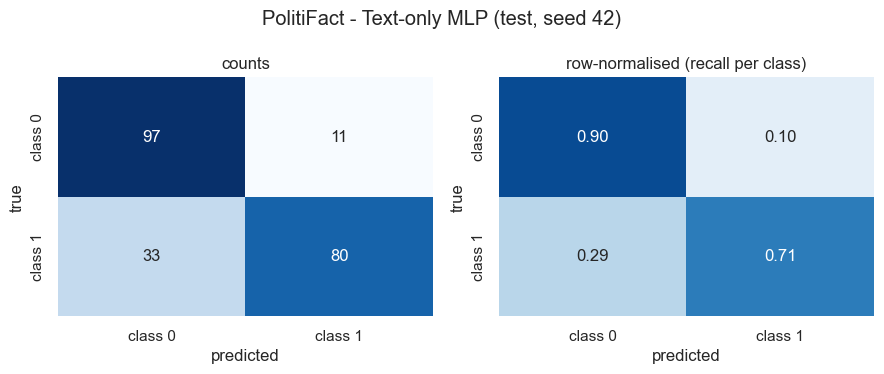

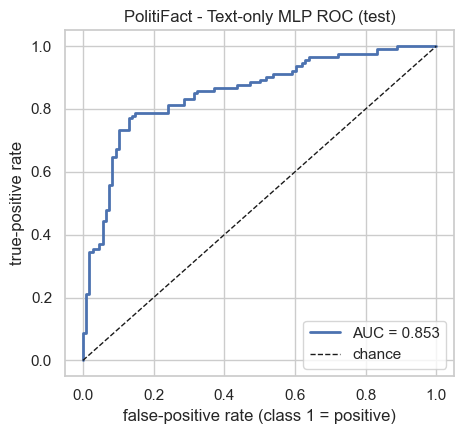

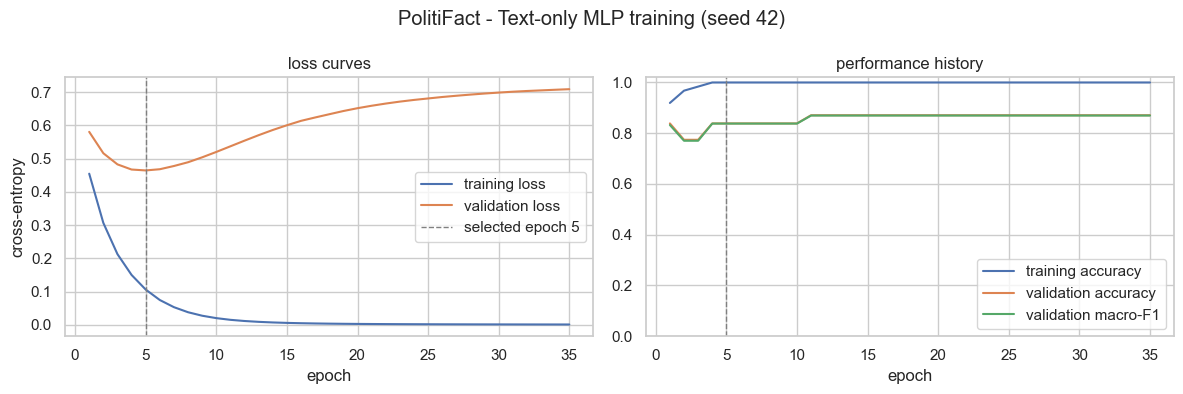


######## Text-only MLP | GossipCop | seed 42 ########


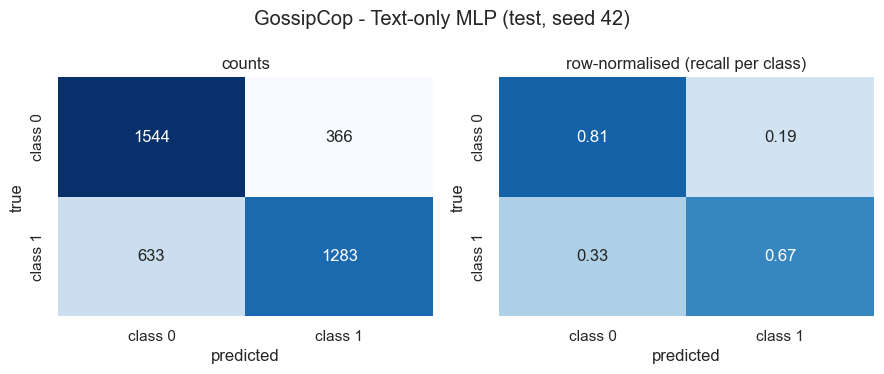

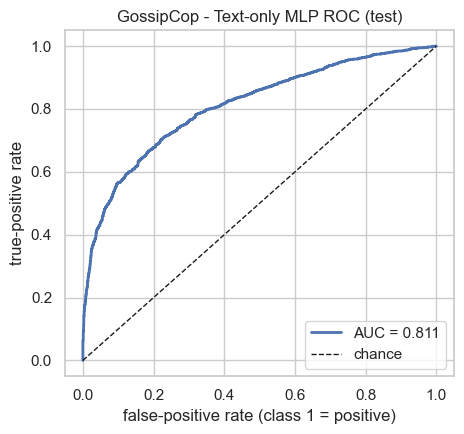

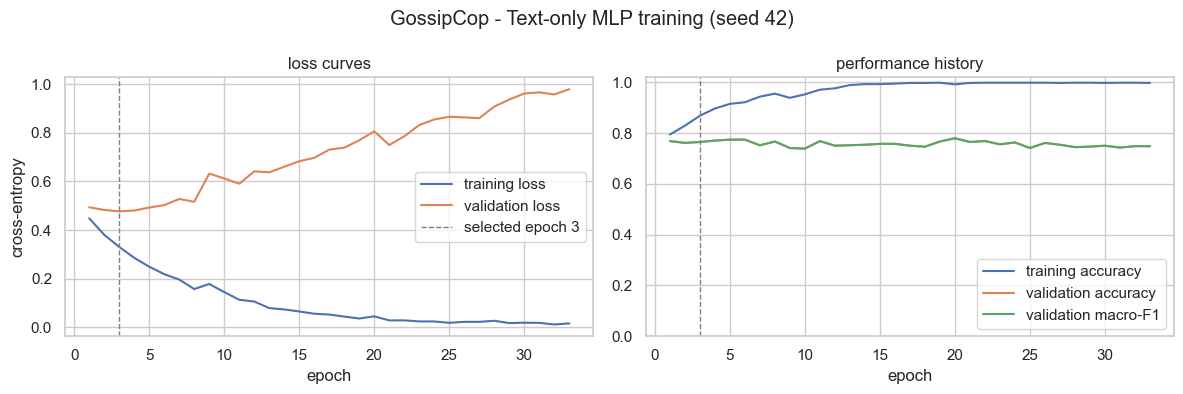


######## Text-only MLP | PolitiFact | seed 43 ########

######## Text-only MLP | GossipCop | seed 43 ########

######## Text-only MLP | PolitiFact | seed 44 ########

######## Text-only MLP | GossipCop | seed 44 ########

######## Text-only MLP | PolitiFact | seed 45 ########

######## Text-only MLP | GossipCop | seed 45 ########

######## Text-only MLP | PolitiFact | seed 46 ########

######## Text-only MLP | GossipCop | seed 46 ########


,dataset,seed,split,n,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,PolitiFact,42,val,31,0.8387,0.8417,0.8504,0.8380,0.8675
1,PolitiFact,42,test,221,0.8009,0.8126,0.8031,0.7997,0.8533
2,GossipCop,42,val,546,0.7656,0.7673,0.7667,0.7655,0.8508
3,GossipCop,42,test,3826,0.7389,0.7436,0.7390,0.7377,0.8108
4,PolitiFact,43,val,31,0.8710,0.8688,0.8782,0.8697,0.8803
5,PolitiFact,43,test,221,0.7964,0.8091,0.7986,0.7950,0.8627
6,GossipCop,43,val,546,0.7674,0.7687,0.7683,0.7674,0.8437
7,GossipCop,43,test,3826,0.7397,0.7440,0.7398,0.7386,0.8078
8,PolitiFact,44,val,31,0.8387,0.8417,0.8504,0.8380,0.8718
9,PolitiFact,44,test,221,0.8281,0.8344,0.8296,0.8276,0.8673


In [12]:
def run_text_mlp(name, seed, hp=MLP_HP, device=DEVICE):
    require_torch()
    title = DATASET_TITLES[name]
    d = TEXT_DATA[name]
    t0 = time.perf_counter()

    Xtr, Xva, Xte = d["train"]["X"], d["val"]["X"], d["test"]["X"]
    scaler_mean, scaler_scale = None, None
    if hp["standardize"]:
        scaler = StandardScaler().fit(Xtr)
        scaler_mean, scaler_scale = scaler.mean_.astype(np.float32), scaler.scale_.astype(np.float32)
        Xtr, Xva, Xte = scaler.transform(Xtr), scaler.transform(Xva), scaler.transform(Xte)

    model, hist, info = train_mlp(Xtr, d["train"]["y"], Xva, d["val"]["y"], seed, hp, device)
    train_time = time.perf_counter() - t0

    rows = []
    preds = {}
    for split, X in (("val", Xva), ("test", Xte)):
        y_true = d[split]["y"]
        y_pred, y_score = predict_mlp(model, X, device)
        preds[split] = (y_true, y_pred, y_score)
        rows.append({"dataset": title, "dataset_key": name, "model": "Text-only MLP", "feature_type": f"root-node {FEATURE} (768-d)",
                     "seed": seed, "split": split, **compute_metrics(y_true, y_pred, y_score)})
    test_row = [r for r in rows if r["split"] == "test"][0]

    tag = f"text_mlp_{name}_seed{seed}"
    hist.to_csv(BASE_LOG_DIR / f"{tag}_history.csv", index=False); _register(BASE_LOG_DIR / f"{tag}_history.csv", "csv")
    ckpt = BASE_CKPT_DIR / "text_mlp" / f"{tag}.pt"
    ckpt.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"state_dict": model.state_dict(), "hyperparameters": hp, "seed": seed, "dataset": name,
                "scaler_mean": None if scaler_mean is None else torch.as_tensor(scaler_mean),
                "scaler_scale": None if scaler_scale is None else torch.as_tensor(scaler_scale),
                "input": "root-node BERT vector (768)"}, ckpt)
    _register(ckpt, "checkpoint")

    y_true, y_pred, y_score = preds["test"]
    plot_confusion(y_true, y_pred, f"{title} - Text-only MLP (test, seed {seed})", BASE_FIG_DIR / "text_mlp" / f"{tag}_confusion_matrix.png")
    plot_roc(y_true, y_score, test_row["roc_auc"], f"{title} - Text-only MLP ROC (test)", BASE_FIG_DIR / "text_mlp" / f"{tag}_roc.png")
    plot_history(hist, info["best_epoch"], f"{title} - Text-only MLP training (seed {seed})", BASE_FIG_DIR / "text_mlp" / f"{tag}_learning_curves.png")

    meta = {"dataset": title, "model": "Text-only MLP", "feature_type": f"root-node {FEATURE} (768-d), graph.x[0] only",
            "uses_text": True, "uses_graph_structure": False, "seed": seed, "hyperparameters": hp,
            "train_graphs": len(d["train"]["y"]), "val_graphs": len(d["val"]["y"]), "test_graphs": len(d["test"]["y"]),
            "device": str(device), "training_time_seconds": round(train_time, 2), **info,
            "selection_criterion": "lowest validation cross-entropy (early stopping)",
            "label_semantics": "unverified (class 0/1)" if FAKE_CLASS_INDEX is None else f"class {FAKE_CLASS_INDEX} = fake",
            "metrics_test": {k: test_row[k] for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc")},
            "versions": versions, "run_id": RUN_ID}
    save_json(meta, BASE_METRICS_DIR / f"{tag}_metadata.json")
    logger.info("MLP %s seed=%d best_epoch=%d epochs=%d time=%.1fs test=%s", name, seed, info["best_epoch"], info["epochs_run"], train_time, meta["metrics_test"])
    return rows


MLP_ROWS = []
for seed in SEEDS:
    SHOW_PLOTS = seed == SEEDS[0]
    for name in DATASETS:
        print(f"\n######## Text-only MLP | {DATASET_TITLES[name]} | seed {seed} ########")
        MLP_ROWS += run_text_mlp(name, seed)
MLP_METRICS = append_run_metrics(MLP_ROWS, BASE_METRICS_DIR / "baseline_text_mlp_metrics.csv")
display(pd.DataFrame(MLP_ROWS)[show_cols].round(4))

## 6 · Baseline B: Propagation-only Random Forest

Input is a set of graph statistics (nodes, depth, degree and leaf measures). Statistics that are exact functions of the node count in the training graphs are dropped. `max_depth` and `min_samples_leaf` are chosen on validation macro-F1.

In [13]:
ALL_STAT_FEATURES = ["num_nodes", "num_edges", "max_depth", "avg_depth", "root_degree",
                     "max_degree", "avg_degree", "degree_std", "leaf_proportion"]

STATS = {}
for name in DATASETS:
    STATS[name] = compute_all_graph_statistics(RAW[name], desc=f"{DATASET_TITLES[name]} structural statistics")
    p = BASE_METRICS_DIR / f"propagation_features_{name}.csv"
    save_dataframe(STATS[name][["graph_idx", "split", "label", "label_raw"] + ALL_STAT_FEATURES + ["is_connected", "is_tree"]], p)
    print(f"{DATASET_TITLES[name]:<11}: {len(STATS[name]):,} graphs -> {p.relative_to(PROJECT_ROOT)}")


def select_rf_features(train_stats):
    dropped = {}
    if (train_stats["num_edges"] == train_stats["num_nodes"] - 1).all():
        dropped["num_edges"] = "equals num_nodes - 1 in every training graph"
    if np.allclose(train_stats["avg_degree"], 2 * (train_stats["num_nodes"] - 1) / train_stats["num_nodes"]):
        dropped["avg_degree"] = "equals 2(n-1)/n in every training graph"
    return [f for f in ALL_STAT_FEATURES if f not in dropped], dropped


RF_FEATURES, RF_DROPPED = {}, {}
for name in DATASETS:
    train_stats = STATS[name][STATS[name]["split"] == "train"]
    RF_FEATURES[name], RF_DROPPED[name] = select_rf_features(train_stats)
    print(f"{DATASET_TITLES[name]:<11}: using {len(RF_FEATURES[name])} features {RF_FEATURES[name]}")
    for f, why in RF_DROPPED[name].items():
        print(f"{'':<13}dropped '{f}' ({why})")
    assert not any(c.startswith("bert") or c == "x" for c in RF_FEATURES[name])

PolitiFact structural statistics:   0%|          | 0/314 [00:00<?, ?it/s]

PolitiFact : 314 graphs -> results\metrics\baselines\propagation_features_politifact.csv


GossipCop structural statistics:   0%|          | 0/5464 [00:00<?, ?it/s]

GossipCop  : 5,464 graphs -> results\metrics\baselines\propagation_features_gossipcop.csv
PolitiFact : using 7 features ['num_nodes', 'max_depth', 'avg_depth', 'root_degree', 'max_degree', 'degree_std', 'leaf_proportion']
             dropped 'num_edges' (equals num_nodes - 1 in every training graph)
             dropped 'avg_degree' (equals 2(n-1)/n in every training graph)
GossipCop  : using 7 features ['num_nodes', 'max_depth', 'avg_depth', 'root_degree', 'max_degree', 'degree_std', 'leaf_proportion']
             dropped 'num_edges' (equals num_nodes - 1 in every training graph)
             dropped 'avg_degree' (equals 2(n-1)/n in every training graph)


In [14]:
def build_structure_dataset(name):
    stats = STATS[name].set_index("graph_idx")
    data = {}
    for s in SPLITS:
        idx = RAW[name]["splits"][s]
        data[s] = {"idx": idx, "X": stats.loc[idx, RF_FEATURES[name]].to_numpy(dtype=np.float64), "y": RAW[name]["y"][idx]}
        assert (stats.loc[idx, "label"].to_numpy() == data[s]["y"]).all()
        assert not np.isnan(data[s]["X"]).any()
    return data


STRUCT_DATA = {name: build_structure_dataset(name) for name in DATASETS}
rows = []
for name in DATASETS:
    for s in SPLITS:
        d = STRUCT_DATA[name][s]
        cnt = np.bincount(d["y"], minlength=2)
        rows.append({"dataset": DATASET_TITLES[name], "split": s, "X shape": d["X"].shape, "class 0": int(cnt[0]), "class 1": int(cnt[1])})
display(pd.DataFrame(rows))

,dataset,split,X shape,class 0,class 1
0,PolitiFact,train,"(62, 7)",36,26
1,PolitiFact,val,"(31, 7)",13,18
2,PolitiFact,test,"(221, 7)",108,113
3,GossipCop,train,"(1092, 7)",557,535
4,GossipCop,val,"(546, 7)",265,281
5,GossipCop,test,"(3826, 7)",1910,1916



######## Propagation-only RF | PolitiFact | seed 42 ########


,max_depth,min_samples_leaf,val_f1_macro,val_roc_auc,val_accuracy
0,NaN,1,0.4493,0.5385,0.4516
1,NaN,3,0.4493,0.5641,0.4516
2,NaN,5,0.5241,0.5897,0.5484
3,4.0,1,0.4561,0.5470,0.4839
4,4.0,3,0.3659,0.5556,0.4194
5,4.0,5,0.4816,0.5726,0.5161
6,8.0,1,0.4833,0.5342,0.4839
7,8.0,3,0.4493,0.5598,0.4516
8,8.0,5,0.5241,0.5897,0.5484


selected on validation: max_depth=None, min_samples_leaf=5, class_weight=None


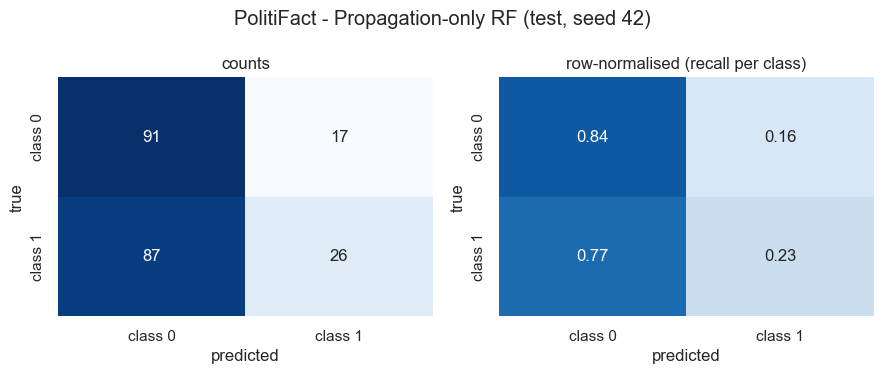

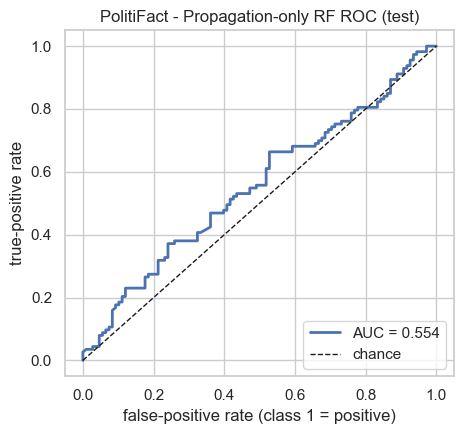

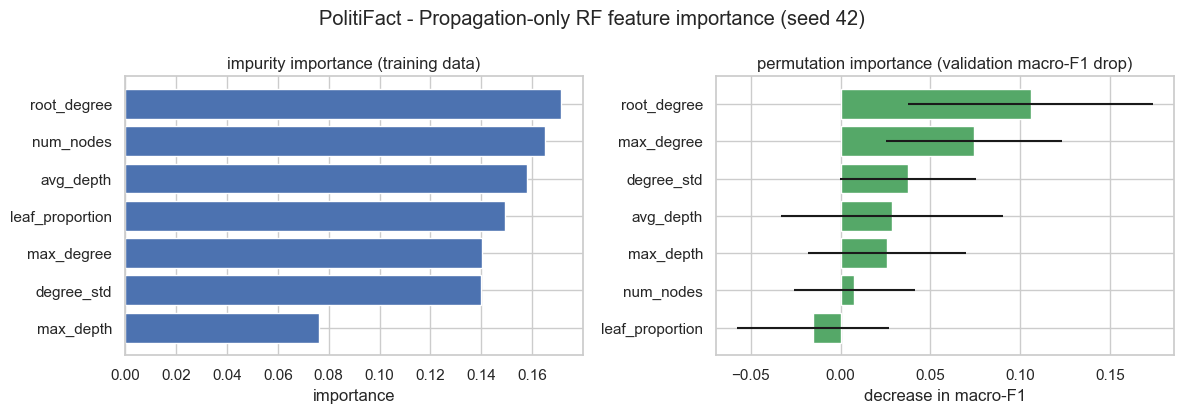

,feature,impurity_importance,permutation_importance_val_mean,permutation_importance_val_std
3,root_degree,0.1714,0.1058,0.0681
0,num_nodes,0.1651,0.0076,0.0338
2,avg_depth,0.1578,0.0287,0.0619
6,leaf_proportion,0.1495,-0.0155,0.0422
4,max_degree,0.1402,0.0741,0.0491
5,degree_std,0.1397,0.0375,0.0380
1,max_depth,0.0763,0.0257,0.0439



######## Propagation-only RF | GossipCop | seed 42 ########


,max_depth,min_samples_leaf,val_f1_macro,val_roc_auc,val_accuracy
0,NaN,1,0.8075,0.8884,0.8077
1,NaN,3,0.8168,0.9004,0.8168
2,NaN,5,0.8241,0.9012,0.8242
3,4.0,1,0.8351,0.9039,0.8352
4,4.0,3,0.8333,0.9055,0.8333
5,4.0,5,0.8315,0.9053,0.8315
6,8.0,1,0.8241,0.9001,0.8242
7,8.0,3,0.8241,0.9035,0.8242
8,8.0,5,0.8260,0.9029,0.8260


selected on validation: max_depth=4, min_samples_leaf=1, class_weight=None


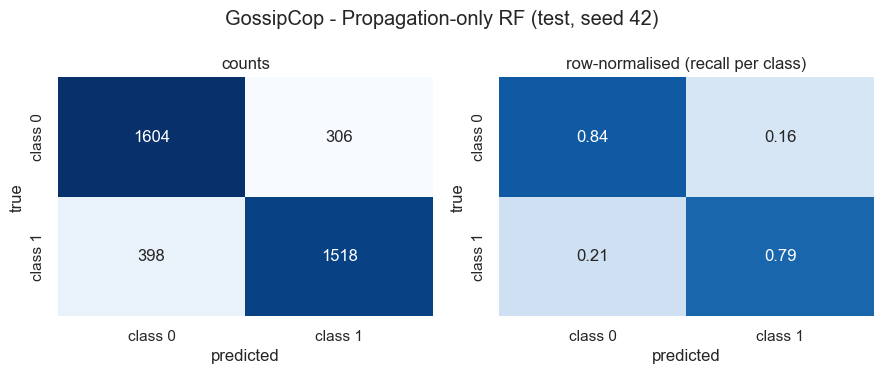

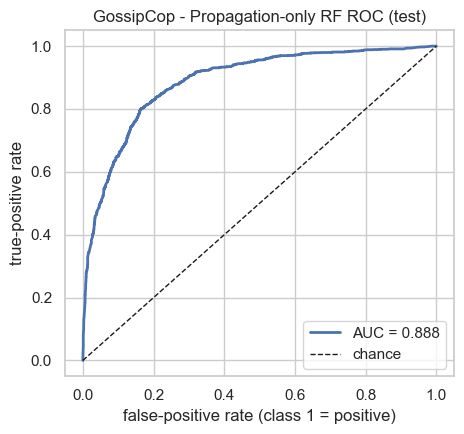

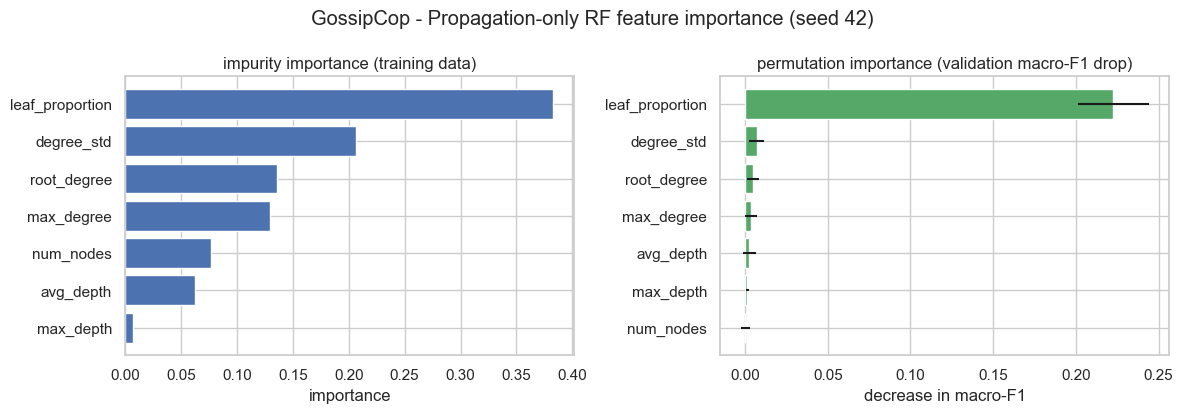

,feature,impurity_importance,permutation_importance_val_mean,permutation_importance_val_std
6,leaf_proportion,0.3824,0.2227,0.0215
5,degree_std,0.2067,0.0069,0.0044
3,root_degree,0.1354,0.0048,0.0038
4,max_degree,0.1296,0.0036,0.0037
0,num_nodes,0.0766,0.0002,0.0028
2,avg_depth,0.0620,0.0025,0.0039
1,max_depth,0.0072,0.0014,0.0008



######## Propagation-only RF | PolitiFact | seed 43 ########
selected on validation: max_depth=None, min_samples_leaf=1, class_weight=None

######## Propagation-only RF | GossipCop | seed 43 ########
selected on validation: max_depth=4, min_samples_leaf=1, class_weight=None

######## Propagation-only RF | PolitiFact | seed 44 ########
selected on validation: max_depth=None, min_samples_leaf=3, class_weight=None


C:\Users\shara\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\shara\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\shara\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
C:\Users\s


######## Propagation-only RF | GossipCop | seed 44 ########
selected on validation: max_depth=4, min_samples_leaf=3, class_weight=None

######## Propagation-only RF | PolitiFact | seed 45 ########
selected on validation: max_depth=None, min_samples_leaf=1, class_weight=None

######## Propagation-only RF | GossipCop | seed 45 ########
selected on validation: max_depth=4, min_samples_leaf=1, class_weight=None

######## Propagation-only RF | PolitiFact | seed 46 ########
selected on validation: max_depth=None, min_samples_leaf=5, class_weight=None

######## Propagation-only RF | GossipCop | seed 46 ########
selected on validation: max_depth=4, min_samples_leaf=1, class_weight=None


,dataset,seed,split,n,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,PolitiFact,42,val,31,0.5484,0.6567,0.6004,0.5241,0.5897
1,PolitiFact,42,test,221,0.5294,0.5579,0.5363,0.4848,0.5537
2,GossipCop,42,val,546,0.8352,0.8353,0.8356,0.8351,0.9039
3,GossipCop,42,test,3826,0.8160,0.8167,0.8160,0.8159,0.8878
4,PolitiFact,43,val,31,0.5161,0.5432,0.5406,0.5141,0.5641
5,PolitiFact,43,test,221,0.5249,0.5429,0.5309,0.4923,0.5648
6,GossipCop,43,val,546,0.8352,0.8355,0.8357,0.8352,0.9044
7,GossipCop,43,test,3826,0.8131,0.8141,0.8132,0.8130,0.8878
8,PolitiFact,44,val,31,0.5484,0.5881,0.5791,0.5441,0.5641
9,PolitiFact,44,test,221,0.5204,0.5401,0.5269,0.4808,0.5690


In [15]:
def run_propagation_rf(name, seed):
    title, d, feats = DATASET_TITLES[name], STRUCT_DATA[name], RF_FEATURES[name]
    t0 = time.perf_counter()
    cnt = np.bincount(d["train"]["y"], minlength=2)
    class_weight = "balanced" if cnt.min() / cnt.sum() < 0.40 else None

    candidates = []
    for max_depth, min_leaf in itertools.product(RF_GRID["max_depth"], RF_GRID["min_samples_leaf"]):
        clf = RandomForestClassifier(**RF_FIXED, max_depth=max_depth, min_samples_leaf=min_leaf,
                                     class_weight=class_weight, random_state=seed, n_jobs=-1)
        clf.fit(d["train"]["X"], d["train"]["y"])
        proba = clf.predict_proba(d["val"]["X"])[:, list(clf.classes_).index(1)]
        m = compute_metrics(d["val"]["y"], clf.predict(d["val"]["X"]), proba)
        candidates.append({"max_depth": max_depth, "min_samples_leaf": min_leaf, "val_f1_macro": m["f1_macro"],
                           "val_roc_auc": m["roc_auc"], "val_accuracy": m["accuracy"], "model": clf})
    key = lambda c: (c["val_f1_macro"], -1 if np.isnan(c["val_roc_auc"]) else c["val_roc_auc"])
    best = max(candidates, key=key)
    clf = best["model"]
    train_time = time.perf_counter() - t0
    grid_df = pd.DataFrame([{k: v for k, v in c.items() if k != "model"} for c in candidates])
    if SHOW_PLOTS:
        display(grid_df.round(4))
    print(f"selected on validation: max_depth={best['max_depth']}, min_samples_leaf={best['min_samples_leaf']}, class_weight={class_weight}")

    rows, preds = [], {}
    pos_col = list(clf.classes_).index(1)
    for split in ("val", "test"):
        y_true = d[split]["y"]
        proba = clf.predict_proba(d[split]["X"])[:, pos_col]
        y_pred = clf.predict(d[split]["X"])
        preds[split] = (y_true, y_pred, proba)
        rows.append({"dataset": title, "dataset_key": name, "model": "Propagation-only RF", "feature_type": "graph structure statistics",
                     "seed": seed, "split": split, **compute_metrics(y_true, y_pred, proba)})
    test_row = [r for r in rows if r["split"] == "test"][0]

    tag = f"propagation_rf_{name}_seed{seed}"
    ckpt = BASE_CKPT_DIR / "propagation_rf" / f"{tag}.joblib"
    ckpt.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({"model": clf, "features": feats, "seed": seed, "dataset": name}, ckpt, compress=3)
    _register(ckpt, "checkpoint")
    save_dataframe(grid_df, BASE_METRICS_DIR / f"{tag}_validation_grid.csv")

    y_true, y_pred, proba = preds["test"]
    plot_confusion(y_true, y_pred, f"{title} - Propagation-only RF (test, seed {seed})", BASE_FIG_DIR / "propagation_rf" / f"{tag}_confusion_matrix.png")
    plot_roc(y_true, proba, test_row["roc_auc"], f"{title} - Propagation-only RF ROC (test)", BASE_FIG_DIR / "propagation_rf" / f"{tag}_roc.png")


    perm = permutation_importance(clf, d["val"]["X"], d["val"]["y"], scoring="f1_macro", n_repeats=20, random_state=seed, n_jobs=1)
    imp = pd.DataFrame({"feature": feats, "impurity_importance": clf.feature_importances_,
                        "permutation_importance_val_mean": perm.importances_mean, "permutation_importance_val_std": perm.importances_std})
    save_dataframe(imp, BASE_METRICS_DIR / f"{tag}_feature_importance.csv")
    order = imp.sort_values("impurity_importance")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    axes[0].barh(order["feature"], order["impurity_importance"], color="#4C72B0")
    axes[0].set_title("impurity importance (training data)"); axes[0].set_xlabel("importance")
    o2 = imp.sort_values("permutation_importance_val_mean")
    axes[1].barh(o2["feature"], o2["permutation_importance_val_mean"], xerr=o2["permutation_importance_val_std"], color="#55A868")
    axes[1].set_title("permutation importance (validation macro-F1 drop)"); axes[1].set_xlabel("decrease in macro-F1")
    fig.suptitle(f"{title} - Propagation-only RF feature importance (seed {seed})"); plt.tight_layout()
    save_figure(fig, BASE_FIG_DIR / "propagation_rf" / f"{tag}_feature_importance.png"); show_or_close(fig)
    if SHOW_PLOTS:
        display(imp.sort_values("impurity_importance", ascending=False).round(4))

    meta = {"dataset": title, "model": "Propagation-only RF", "feature_type": "graph structure statistics (no text)",
            "uses_text": False, "uses_graph_structure": True, "features_used": feats, "features_dropped_as_redundant": RF_DROPPED[name],
            "seed": seed, "fixed_hyperparameters": RF_FIXED, "tuning_grid": RF_GRID,
            "selected_hyperparameters": {"max_depth": best["max_depth"], "min_samples_leaf": best["min_samples_leaf"], "class_weight": class_weight},
            "selection_criterion": "validation macro-F1 (tie-break: validation ROC-AUC)",
            "train_graphs": len(d["train"]["y"]), "val_graphs": len(d["val"]["y"]), "test_graphs": len(d["test"]["y"]),
            "device": "cpu (scikit-learn)", "training_time_seconds": round(train_time, 2),
            "label_semantics": "unverified (class 0/1)" if FAKE_CLASS_INDEX is None else f"class {FAKE_CLASS_INDEX} = fake",
            "metrics_test": {k: test_row[k] for k in ("accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc")},
            "versions": versions, "run_id": RUN_ID}
    save_json(meta, BASE_METRICS_DIR / f"{tag}_metadata.json")
    logger.info("RF %s seed=%d selected=%s time=%.1fs test=%s", name, seed, meta["selected_hyperparameters"], train_time, meta["metrics_test"])
    return rows


RF_ROWS = []
for seed in SEEDS:
    SHOW_PLOTS = seed == SEEDS[0]
    for name in DATASETS:
        print(f"\n######## Propagation-only RF | {DATASET_TITLES[name]} | seed {seed} ########")
        RF_ROWS += run_propagation_rf(name, seed)
RF_METRICS = append_run_metrics(RF_ROWS, BASE_METRICS_DIR / "baseline_propagation_rf_metrics.csv")
display(pd.DataFrame(RF_ROWS)[show_cols].round(4))

## 7 · Comparison (test split, mean ± std over seeds)

In [16]:
def wilson_interval(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


parts = []
for fname in ("baseline_text_mlp_metrics.csv", "baseline_propagation_rf_metrics.csv"):
    p = BASE_METRICS_DIR / fname
    if p.is_file():
        parts.append(pd.read_csv(p))
    else:
        print(f"WARNING: {fname} not found - that baseline has not been run (or failed); it is missing from the comparison.")
if not parts:
    raise RuntimeError("No baseline metrics found. Run Sections 3 and 4 first.")
ALL_METRICS = pd.concat(parts, ignore_index=True)
TEST = ALL_METRICS[ALL_METRICS["split"] == "test"]

metric_cols = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc"]
agg = TEST.groupby(["dataset", "model"], sort=False)[metric_cols].mean().reset_index()
stds = TEST.groupby(["dataset", "model"], sort=False)[metric_cols].std().reset_index()
n_seeds = TEST.groupby(["dataset", "model"], sort=False)["seed"].nunique().reset_index(name="n_seeds")
n_test = TEST.groupby(["dataset", "model"], sort=False)["n"].first().reset_index()
agg = agg.merge(n_seeds).merge(n_test)
lo_hi = [wilson_interval(round(a * n), n) for a, n in zip(agg["accuracy"], agg["n"])]
agg["accuracy_ci95_low"], agg["accuracy_ci95_high"] = [x[0] for x in lo_hi], [x[1] for x in lo_hi]

COMPARISON = agg.rename(columns={"accuracy": "Accuracy", "precision_macro": "Precision (macro)", "recall_macro": "Recall (macro)",
                                 "f1_macro": "Macro F1", "roc_auc": "ROC-AUC", "dataset": "Dataset", "model": "Model",
                                 "n": "test graphs", "n_seeds": "seeds"})
order_models = {"Text-only MLP": 0, "Propagation-only RF": 1}
order_ds = {DATASET_TITLES[n]: i for i, n in enumerate(DATASETS)}
COMPARISON = COMPARISON.sort_values(by=["Dataset", "Model"], key=lambda s: s.map({**order_models, **order_ds})).reset_index(drop=True)
save_dataframe(COMPARISON, BASE_METRICS_DIR / "baseline_comparison.csv")
display(COMPARISON.round(4))

if (TEST["seed"].nunique() > 1):
    save_dataframe(stds.rename(columns=lambda c: f"{c}_std" if c in metric_cols else c), BASE_METRICS_DIR / "baseline_comparison_std_over_seeds.csv")

def mean_std(col):
    g = TEST.groupby(["dataset", "model"], sort=False)[col].agg(["mean", "std"])
    return g.apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}" if not np.isnan(r["std"]) else f"{r['mean']:.3f}", axis=1)


SUMMARY_TABLE = pd.DataFrame({"Accuracy": mean_std("accuracy"), "Macro F1": mean_std("f1_macro"), "ROC-AUC": mean_std("roc_auc")}).reset_index()
SUMMARY_TABLE = SUMMARY_TABLE.rename(columns={"dataset": "Dataset", "model": "Model"})
save_dataframe(SUMMARY_TABLE, BASE_METRICS_DIR / "baseline_summary_mean_std.csv")
display(SUMMARY_TABLE)

print("\nMajority-class accuracy on each test split (floor for comparison):")
for name in DATASETS:
    yt = RAW[name]["y"][RAW[name]["splits"]["test"]]
    print(f"  {DATASET_TITLES[name]:<11}: {np.bincount(yt).max() / len(yt):.3f}  ({len(yt)} test graphs; one graph = {100 / len(yt):.2f} accuracy points)")

,Dataset,Model,Accuracy,Precision (macro),Recall (macro),Macro F1,ROC-AUC,seeds,test graphs,accuracy_ci95_low,accuracy_ci95_high
0,PolitiFact,Text-only MLP,0.8127,0.8220,0.8146,0.8118,0.8628,5,221,0.7580,0.8602
1,PolitiFact,Propagation-only RF,0.5195,0.5369,0.5255,0.4856,0.5590,5,221,0.4547,0.5853
2,GossipCop,Text-only MLP,0.7404,0.7454,0.7405,0.7391,0.8106,5,3826,0.7263,0.7541
3,GossipCop,Propagation-only RF,0.8152,0.8160,0.8152,0.8151,0.8881,5,3826,0.8026,0.8272


,Dataset,Model,Accuracy,Macro F1,ROC-AUC
0,PolitiFact,Text-only MLP,0.813 ± 0.017,0.812 ± 0.017,0.863 ± 0.006
1,GossipCop,Text-only MLP,0.740 ± 0.004,0.739 ± 0.004,0.811 ± 0.007
2,PolitiFact,Propagation-only RF,0.519 ± 0.009,0.486 ± 0.005,0.559 ± 0.011
3,GossipCop,Propagation-only RF,0.815 ± 0.001,0.815 ± 0.001,0.888 ± 0.001



Majority-class accuracy on each test split (floor for comparison):
  PolitiFact : 0.511  (221 test graphs; one graph = 0.45 accuracy points)
  GossipCop  : 0.501  (3826 test graphs; one graph = 0.03 accuracy points)


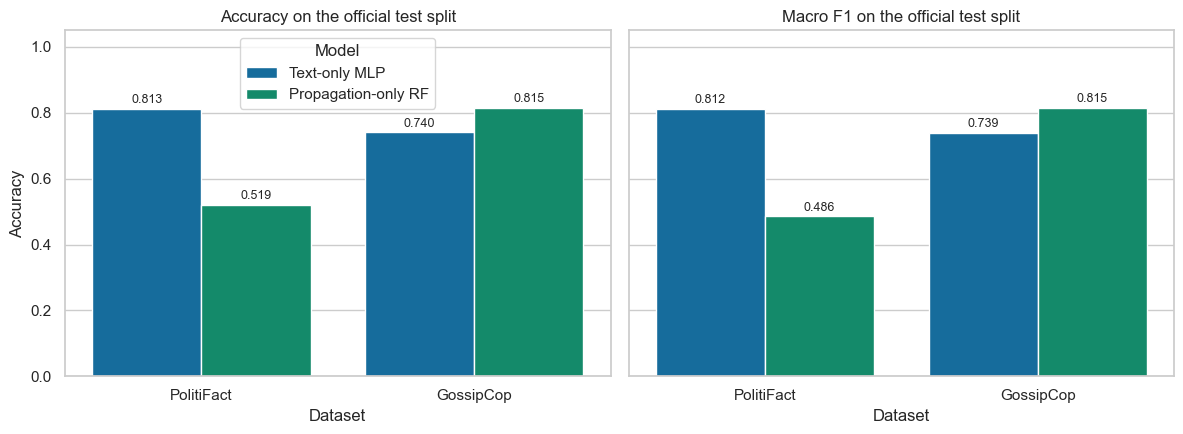

In [17]:
long = COMPARISON.melt(id_vars=["Dataset", "Model"], value_vars=["Accuracy", "Macro F1"], var_name="metric", value_name="value")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
model_palette = {"Text-only MLP": "#0072B2", "Propagation-only RF": "#009E73"}
for ax, metric in zip(axes, ["Accuracy", "Macro F1"]):
    sub = long[long.metric == metric]
    sns.barplot(data=sub, x="Dataset", y="value", hue="Model", palette=model_palette, ax=ax)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.3f", fontsize=9, padding=2)
    ax.set_ylim(0, 1.05); ax.set_ylabel(metric); ax.set_title(f"{metric} on the official test split")
axes[1].get_legend().remove() if axes[1].get_legend() else None
plt.tight_layout()
save_figure(fig, BASE_FIG_DIR / "baseline_comparison_accuracy_f1.png")
plt.show()

## 8 · Observations

In [18]:
C = COMPARISON.set_index(["Dataset", "Model"])
lines = []
for name in DATASETS:
    t = DATASET_TITLES[name]
    have = [m for m in order_models if (t, m) in C.index]
    for m in have:
        r = C.loc[(t, m)]
        lines.append(f"[{t}] {m}: accuracy {r['Accuracy']:.3f} (95% CI {r['accuracy_ci95_low']:.3f}-{r['accuracy_ci95_high']:.3f}), "
                     f"macro-F1 {r['Macro F1']:.3f}, ROC-AUC {r['ROC-AUC']:.3f}.")
    if len(have) == 2:
        a, b = C.loc[(t, "Text-only MLP")], C.loc[(t, "Propagation-only RF")]
        better = "text-only MLP" if a["Macro F1"] > b["Macro F1"] else "propagation-only RF"
        lines.append(f"[{t}] the {better} has the higher macro-F1 (difference {abs(a['Macro F1'] - b['Macro F1']):.3f}); "
                     f"ROC-AUC difference {abs(a['ROC-AUC'] - b['ROC-AUC']):.3f}.")
for m in order_models:
    ts = [(t, C.loc[(t, m)]["Macro F1"]) for t in (DATASET_TITLES[n] for n in DATASETS) if (t, m) in C.index]
    if len(ts) == 2:
        lines.append(f"{m}: macro-F1 is {ts[0][1]:.3f} on {ts[0][0]} vs {ts[1][1]:.3f} on {ts[1][0]}.")
print("\n".join("- " + l for l in lines))

- [PolitiFact] Text-only MLP: accuracy 0.813 (95% CI 0.758-0.860), macro-F1 0.812, ROC-AUC 0.863.
- [PolitiFact] Propagation-only RF: accuracy 0.519 (95% CI 0.455-0.585), macro-F1 0.486, ROC-AUC 0.559.
- [PolitiFact] the text-only MLP has the higher macro-F1 (difference 0.326); ROC-AUC difference 0.304.
- [GossipCop] Text-only MLP: accuracy 0.740 (95% CI 0.726-0.754), macro-F1 0.739, ROC-AUC 0.811.
- [GossipCop] Propagation-only RF: accuracy 0.815 (95% CI 0.803-0.827), macro-F1 0.815, ROC-AUC 0.888.
- [GossipCop] the propagation-only RF has the higher macro-F1 (difference 0.076); ROC-AUC difference 0.078.
- Text-only MLP: macro-F1 is 0.812 on PolitiFact vs 0.739 on GossipCop.
- Propagation-only RF: macro-F1 is 0.486 on PolitiFact vs 0.815 on GossipCop.


Notes: PolitiFact has a small test split (one graph moves accuracy by a visible amount), and the two datasets differ in size and domain, so rankings can differ.

## 9 · Saved files

In [19]:
logger.info("Notebook 02 finished.")
inventory = pd.DataFrame(SAVED_ARTIFACTS)
display(inventory)
print(f"\nFiles written by this notebook: {len(inventory)}  |  log file: {LOG_PATH.relative_to(PROJECT_ROOT)}")
print("Saved metric CSVs:", sorted(p.name for p in BASE_METRICS_DIR.glob("baseline_*.csv")))

,kind,path,size_kB
0,csv,results\logs\baselines\text_mlp_politifact_see...,3.0
1,checkpoint,results\checkpoints\baselines\text_mlp\text_ml...,395.1
2,figure,results\figures\baselines\text_mlp\text_mlp_po...,38.0
3,figure,results\figures\baselines\text_mlp\text_mlp_po...,41.5
4,figure,results\figures\baselines\text_mlp\text_mlp_po...,81.7
...,...,...,...
133,csv,results\metrics\baselines\baseline_propagation...,5.9
134,csv,results\metrics\baselines\baseline_comparison.csv,0.8
135,csv,results\metrics\baselines\baseline_comparison_...,0.6
136,csv,results\metrics\baselines\baseline_summary_mea...,0.3



Files written by this notebook: 138  |  log file: results\logs\baselines\baselines_20261108_130203.log
Saved metric CSVs: ['baseline_comparison.csv', 'baseline_comparison_std_over_seeds.csv', 'baseline_propagation_rf_metrics.csv', 'baseline_summary_mean_std.csv', 'baseline_text_mlp_metrics.csv']
